In [ ]:
# ============================================================
# TASK 1: DATA ACQUISITION AND LOADING
# ============================================================

!pip install -q scikeras tensorflow scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, roc_auc_score
)

from scikeras.wrappers import KerasClassifier
from tensorflow import keras
from tensorflow.keras import layers

# Load Pima Indians Diabetes dataset
url = (
    "https://raw.githubusercontent.com/"
    "jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
)

columns = [
    "Pregnancies", "Glucose", "BloodPressure",
    "SkinThickness", "Insulin", "BMI",
    "DiabetesPedigreeFunction", "Age", "Outcome"
]

df = pd.read_csv(url, names=columns)

print("Dataset loaded successfully!")
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["Outcome"].value_counts())

Dataset loaded successfully!

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset shape: (768, 9)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  ----- 

Missing values after zero-value correction:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Feature shape: (768, 8)
Target shape: (768,)

Training samples: 614
Testing samples: 154


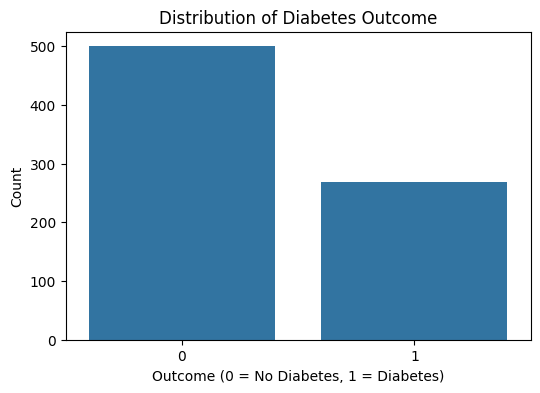

In [ ]:
# ============================================================
# TASK 2: DATA PREPROCESSING
# ============================================================

# Replace biologically implausible zero values with NaN
# Pregnancies and Outcome are excluded because zero is valid.
invalid_zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df[invalid_zero_columns] = df[invalid_zero_columns].replace(
    0, np.nan
)

print("Missing values after zero-value correction:")
print(df.isnull().sum())

# Separate features and target
X = df.drop("Outcome", axis=1)
y = df["Outcome"].astype(int)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# Visualize target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Outcome")
plt.title("Distribution of Diabetes Outcome")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Count")
plt.show()

In [ ]:
# ============================================================
# TASK 3: DEEP LEARNING MODEL
# ============================================================

def build_model(
    meta,
    hidden_neurons=16,
    activation="relu",
    init_mode="he_uniform",
    dropout_rate=0.2,
    learning_rate=0.001
):
    model = keras.Sequential([
        keras.Input(shape=(meta["n_features_in_"],)),

        layers.Dense(
            units=hidden_neurons,
            activation=activation,
            kernel_initializer=init_mode
        ),

        layers.Dropout(dropout_rate),

        layers.Dense(
            units=max(hidden_neurons // 2, 4),
            activation=activation,
            kernel_initializer=init_mode
        ),

        layers.Dense(1, activation="sigmoid")
    ])

    optimizer = keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


print("Deep learning model function defined successfully!")

Deep learning model function defined successfully!


In [ ]:
# ============================================================
# GRID SEARCH HYPERPARAMETER TUNING
# ============================================================

!pip install -q scikeras tensorflow scikit-learn

# Patch SciKeras compatibility issue with scikit-learn 1.6+
import scikeras
from sklearn.utils._tags import ClassifierTags

# 1. Clean up and restore the original initialization of ClassifierTags if it was patched
if hasattr(ClassifierTags.__init__, "__wrapped__") or "patched_init" in ClassifierTags.__init__.__name__:
    # Reload the module dynamically to restore original class definitions cleanly
    import importlib
    import sklearn.utils._tags
    importlib.reload(sklearn.utils._tags)
    from sklearn.utils._tags import ClassifierTags

# 2. Create a clean proxy wrapper class that delegates everything except requires_fit
class PatchedClassifierTags:
    def __init__(self):
        self._tags = ClassifierTags()
        self.requires_fit = True

    def __getattr__(self, name):
        return getattr(self._tags, name)

def patched_sklearn_tags(self):
    return PatchedClassifierTags()

# Dynamically inject the missing method into SciKeras base wrappers
scikeras.wrappers.BaseWrapper.__sklearn_tags__ = patched_sklearn_tags

# Wrap Keras model for Scikit-learn
keras_classifier = KerasClassifier(
    model=build_model,
    verbose=0,
    random_state=42
)

# Preprocessing pipeline
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", keras_classifier)
])

# Hyperparameter grid
param_grid = {
    "classifier__batch_size": [16, 32],
    "classifier__epochs": [20, 30],

    "classifier__model__learning_rate": [0.001, 0.01],

    "classifier__model__init_mode": [
        "uniform", "he_uniform"
    ],

    "classifier__model__activation": [
        "relu", "tanh"
    ],

    "classifier__model__dropout_rate": [
        0.0, 0.2
    ],

    "classifier__model__hidden_neurons": [
        8, 16
    ]
}

# Grid Search with 3-fold cross-validation
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=3,
    n_jobs=1,
    verbose=2,
    refit=True,
    error_score="raise"
)

print("Starting Grid Search...")
print("Total parameter combinations:", 128)
print("Total model fits:", 128 * 3)

grid_search.fit(X_train, y_train)

print("\nGrid Search completed!")
print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(grid_search.best_score_, 4))

Starting Grid Search...
Total parameter combinations: 128
Total model fits: 384
Fitting 3 folds for each of 128 candidates, totalling 384 fits
[CV] END classifier__batch_size=16, classifier__epochs=20, classifier__model__activation=relu, classifier__model__dropout_rate=0.0, classifier__model__hidden_neurons=8, classifier__model__init_mode=uniform, classifier__model__learning_rate=0.001; total time=   9.0s
[CV] END classifier__batch_size=16, classifier__epochs=20, classifier__model__activation=relu, classifier__model__dropout_rate=0.0, classifier__model__hidden_neurons=8, classifier__model__init_mode=uniform, classifier__model__learning_rate=0.001; total time=   4.0s
[CV] END classifier__batch_size=16, classifier__epochs=20, classifier__model__activation=relu, classifier__model__dropout_rate=0.0, classifier__model__hidden_neurons=8, classifier__model__init_mode=uniform, classifier__model__learning_rate=0.001; total time=   4.0s
[CV] END classifier__batch_size=16, classifier__epochs=20, 

[CV] END classifier__batch_size=32, classifier__epochs=20, classifier__model__activation=relu, classifier__model__dropout_rate=0.0, classifier__model__hidden_neurons=8, classifier__model__init_mode=uniform, classifier__model__learning_rate=0.001; total time=   3.5s


[CV] END classifier__batch_size=32, classifier__epochs=20, classifier__model__activation=relu, classifier__model__dropout_rate=0.0, classifier__model__hidden_neurons=8, classifier__model__init_mode=uniform, classifier__model__learning_rate=0.001; total time=   3.7s
[CV] END classifier__batch_size=32, classifier__epochs=20, classifier__model__activation=relu, classifier__model__dropout_rate=0.0, classifier__model__hidden_neurons=8, classifier__model__init_mode=uniform, classifier__model__learning_rate=0.01; total time=   3.5s
[CV] END classifier__batch_size=32, classifier__epochs=20, classifier__model__activation=relu, classifier__model__dropout_rate=0.0, classifier__model__hidden_neurons=8, classifier__model__init_mode=uniform, classifier__model__learning_rate=0.01; total time=   3.4s
[CV] END classifier__batch_size=32, classifier__epochs=20, classifier__model__activation=relu, classifier__model__dropout_rate=0.0, classifier__model__hidden_neurons=8, classifier__model__init_mode=unifor

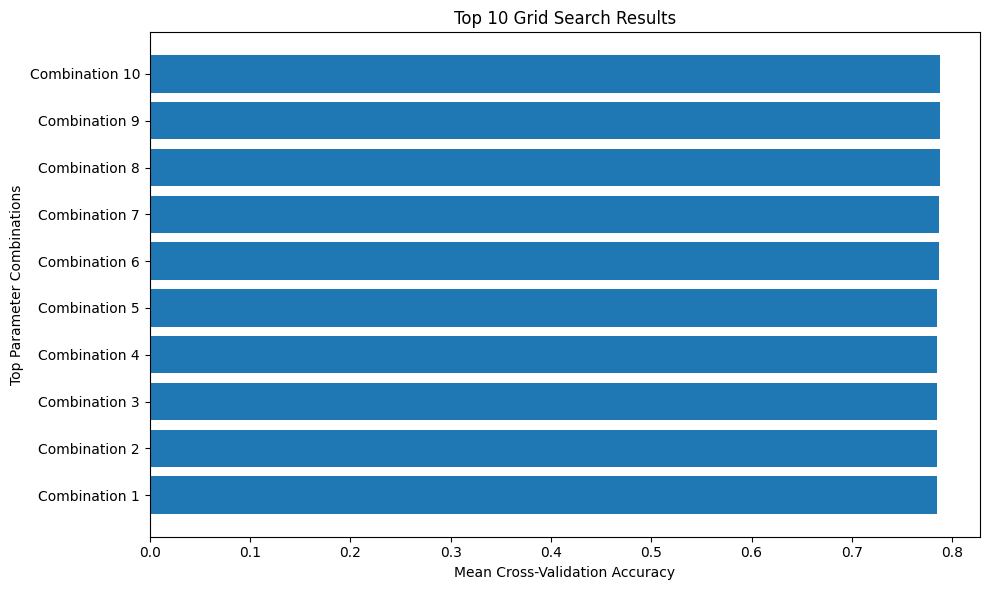


Top 10 parameter combinations:
                                                                                                                                                                                                                                                                   params  mean_test_score  std_test_score
   {'classifier__batch_size': 32, 'classifier__epochs': 20, 'classifier__model__activation': 'tanh', 'classifier__model__dropout_rate': 0.0, 'classifier__model__hidden_neurons': 8, 'classifier__model__init_mode': 'uniform', 'classifier__model__learning_rate': 0.01}         0.788307        0.017596
 {'classifier__batch_size': 16, 'classifier__epochs': 20, 'classifier__model__activation': 'tanh', 'classifier__model__dropout_rate': 0.0, 'classifier__model__hidden_neurons': 16, 'classifier__model__init_mode': 'uniform', 'classifier__model__learning_rate': 0.001}         0.788299        0.011743
 {'classifier__batch_size': 16, 'classifier__epochs': 20, 'classifier__

In [ ]:
# ============================================================
# GRID SEARCH RESULTS VISUALIZATION
# ============================================================

results = pd.DataFrame(grid_search.cv_results_)

top_results = results.nlargest(
    10, "mean_test_score"
).sort_values("mean_test_score")

plt.figure(figsize=(10, 6))

plt.barh(
    range(len(top_results)),
    top_results["mean_test_score"]
)

plt.yticks(
    range(len(top_results)),
    [f"Combination {i+1}" for i in range(len(top_results))]
)

plt.xlabel("Mean Cross-Validation Accuracy")
plt.ylabel("Top Parameter Combinations")
plt.title("Top 10 Grid Search Results")
plt.tight_layout()
plt.show()

print("\nTop 10 parameter combinations:")
print(
    results.nlargest(10, "mean_test_score")[
        ["params", "mean_test_score", "std_test_score"]
    ].to_string(index=False)
)

In [ ]:
# ============================================================
# FINAL SUMMARY
# ============================================================

# Generate predictions on the test set using the best estimator from Grid Search
best_pipeline = grid_search.best_estimator_
y_pred = best_pipeline.predict(X_test)
y_prob = best_pipeline.predict_proba(X_test)[:, 1]

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)






print("========== FINAL SUMMARY ==========")
print("Dataset: Pima Indians Diabetes")
print("Algorithm: Deep Learning Neural Network")
print("Optimization: GridSearchCV")
print("Cross-validation folds: 3")

print("\nBest Hyperparameters:")
for parameter, value in grid_search.best_params_.items():
    print(f"{parameter}: {value}")

print(
    f"\nBest CV Accuracy: "
    f"{grid_search.best_score_ * 100:.2f}%"
)

print(
    f"Test Accuracy: "
    f"{accuracy * 100:.2f}%"
)

print(
    f"Test ROC-AUC: "
    f"{roc_auc_score(y_test, y_prob):.4f}"
)

========== FINAL SUMMARY ==========
Dataset: Pima Indians Diabetes
Algorithm: Deep Learning Neural Network
Optimization: GridSearchCV
Cross-validation folds: 3

Best Hyperparameters:
classifier__batch_size: 32
classifier__epochs: 20
classifier__model__activation: tanh
classifier__model__dropout_rate: 0.0
classifier__model__hidden_neurons: 8
classifier__model__init_mode: uniform
classifier__model__learning_rate: 0.01

Best CV Accuracy: 78.83%
Test Accuracy: 72.08%
Test ROC-AUC: 0.8222
